# 🎓 Student Performance Prediction

A machine learning project that analyzes student-related data and **predicts academic performance** (`Performance Index`) from study habits and background features.

**Pipeline**

1. Setup & data loading
2. Data cleaning and preprocessing
3. Exploratory data analysis (EDA)
4. Feature engineering *(extra features to make the models stronger)*
5. Training and evaluating regression models (with cross-validation)
6. Hyperparameter tuning
7. Visualizing important results (predictions, residuals, feature importance)
8. Predicting for **10 students** (real test students + brand-new students)
9. Saving the model & conclusions

**Tools:** Python · Pandas · NumPy · Scikit-learn · Matplotlib (+ Seaborn for styling)

> Make sure `Student_Performance.csv` is in the same folder as this notebook.

## 1. Setup & Data Loading

In [42]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from IPython.display import display

from sklearn.model_selection import train_test_split, cross_val_score, KFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.titleweight"] = "bold"
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

RANDOM_STATE = 42
TARGET = "Performance Index"

In [43]:
df = pd.read_csv("Student_Performance.csv")
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")
display(df.head(10))

Rows: 10,000 | Columns: 6


,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.000
1,4,82,No,4,2,65.000
2,8,51,Yes,7,2,45.000
3,5,52,Yes,5,2,36.000
4,7,75,No,8,5,66.000
5,3,78,No,9,6,61.000
6,7,73,Yes,5,6,63.000
7,8,45,Yes,4,6,42.000
8,5,77,No,8,2,61.000
9,4,89,No,4,0,69.000


In [44]:
df.info()
display(df.describe().T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hours Studied                     10000 non-null  int64  
 1   Previous Scores                   10000 non-null  int64  
 2   Extracurricular Activities        10000 non-null  object 
 3   Sleep Hours                       10000 non-null  int64  
 4   Sample Question Papers Practiced  10000 non-null  int64  
 5   Performance Index                 10000 non-null  float64
dtypes: float64(1), int64(4), object(1)
memory usage: 468.9+ KB


,count,mean,std,min,25%,50%,75%,max
Hours Studied,"10,000.000",4.993,2.589,1.000,3.000,5.000,7.000,9.000
Previous Scores,"10,000.000",69.446,17.343,40.000,54.000,69.000,85.000,99.000
Sleep Hours,"10,000.000",6.531,1.696,4.000,5.000,7.000,8.000,9.000
Sample Question Papers Practiced,"10,000.000",4.583,2.867,0.000,2.000,5.000,7.000,9.000
Performance Index,"10,000.000",55.225,19.213,10.000,40.000,55.000,71.000,100.000


## 2. Data Cleaning & Preprocessing

Checks: column names, missing values, duplicates, categorical encoding, and outliers.

In [45]:
# 2.1 Tidy column names
df.columns = df.columns.str.strip()

# 2.2 Missing values
missing = df.isna().sum()
print("Missing values per column:")
display(missing.to_frame("missing"))

# 2.3 Duplicates
n_dup = df.duplicated().sum()
print(f"Duplicate rows: {n_dup}")
df = df.drop_duplicates().reset_index(drop=True)
print(f"Rows after dropping duplicates: {len(df):,}")

Missing values per column:


,missing
Hours Studied,0
Previous Scores,0
Extracurricular Activities,0
Sleep Hours,0
Sample Question Papers Practiced,0
Performance Index,0


Duplicate rows: 127
Rows after dropping duplicates: 9,873


In [46]:
# 2.4 Encode the categorical column (Yes/No -> 1/0)
print("Unique values:", df["Extracurricular Activities"].unique())
df["Extracurricular Activities"] = df["Extracurricular Activities"].str.strip().str.title().map({"Yes": 1, "No": 0})
assert df["Extracurricular Activities"].notna().all(), "Unexpected category found"

# 2.5 Outlier check (IQR rule) - reported only, nothing is removed because all values are valid
rows = []
for col in df.columns:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    rows.append((col, n_out))
display(pd.DataFrame(rows, columns=["Column", "IQR outliers"]).set_index("Column"))
print("Clean dataset shape:", df.shape)

Unique values: ['Yes' 'No']


,IQR outliers
Column,
Hours Studied,0
Previous Scores,0
Extracurricular Activities,0
Sleep Hours,0
Sample Question Papers Practiced,0
Performance Index,0


Clean dataset shape: (9873, 6)


## 3. Exploratory Data Analysis

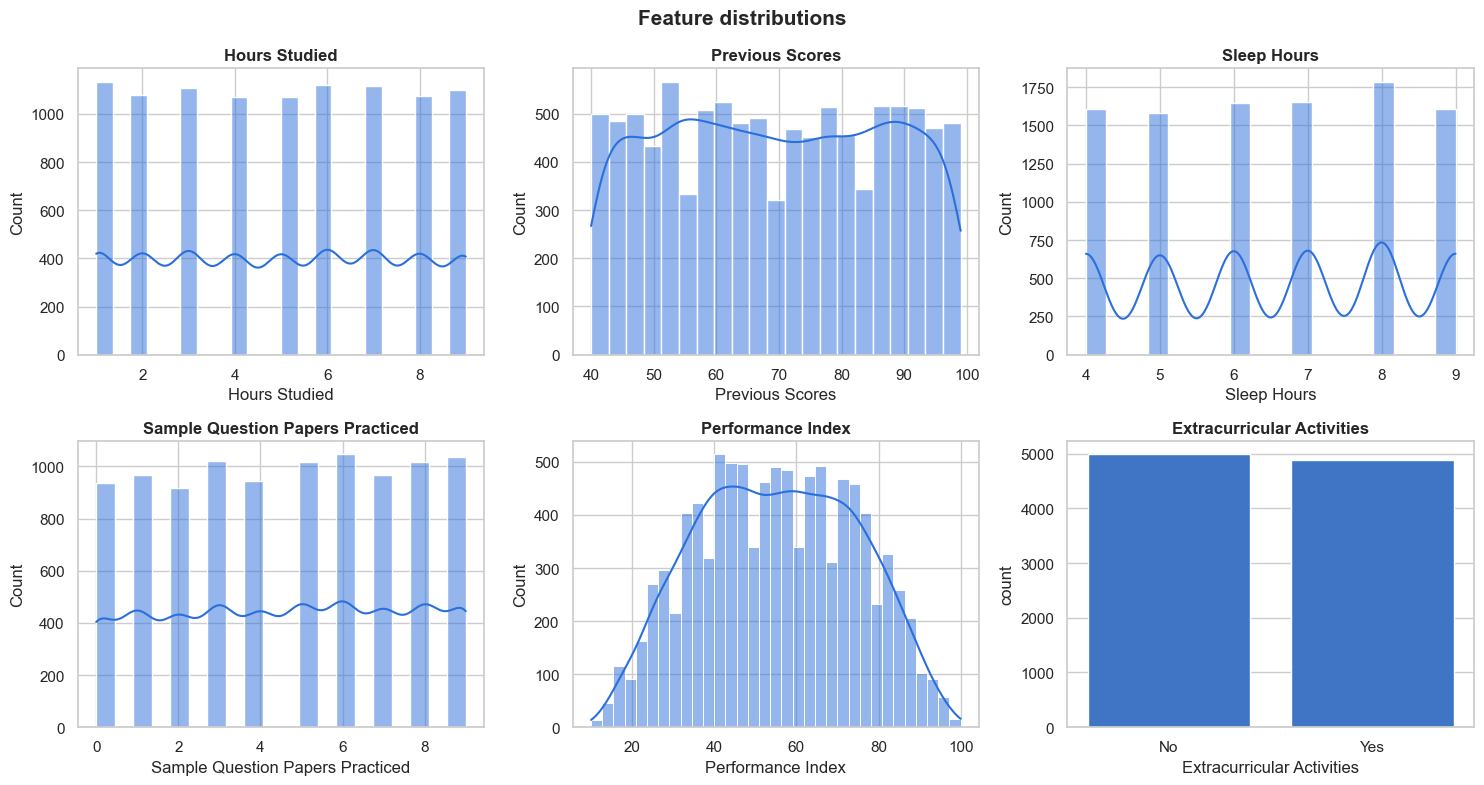

In [47]:
# 3.1 Distributions
num_cols = ["Hours Studied", "Previous Scores", "Sleep Hours", "Sample Question Papers Practiced", TARGET]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(df[col], kde=True, ax=ax, color="#2a6fdb")
    ax.set_title(col)
sns.countplot(x="Extracurricular Activities", data=df, ax=axes[1, 2], color="#2a6fdb")
axes[1, 2].set_xticklabels(["No", "Yes"])
axes[1, 2].set_title("Extracurricular Activities")
plt.suptitle("Feature distributions", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

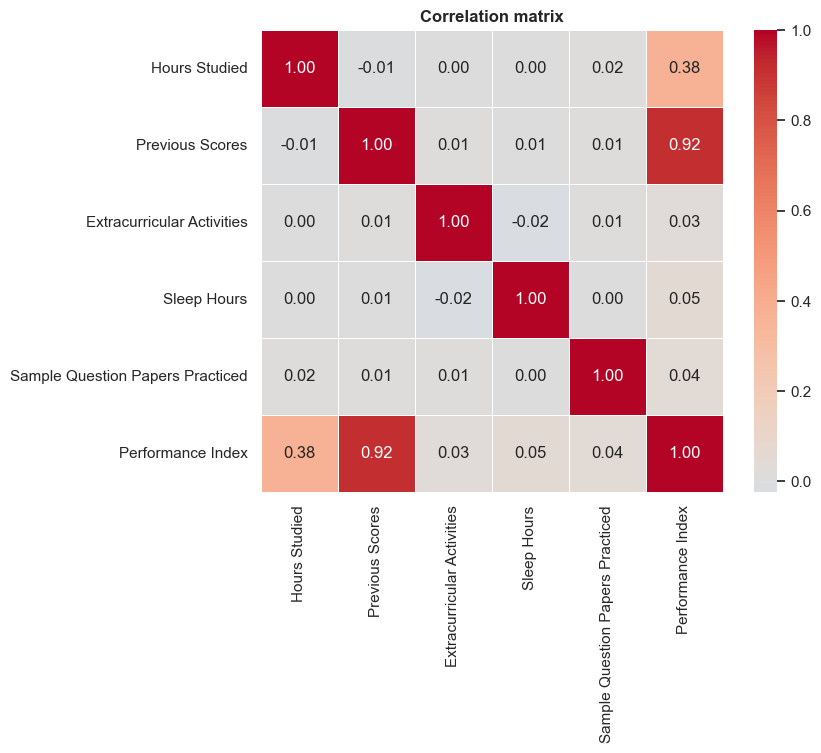

Correlation with the target:


,corr
Previous Scores,0.915
Hours Studied,0.375
Sleep Hours,0.050
Sample Question Papers Practiced,0.043
Extracurricular Activities,0.026


In [48]:
# 3.2 Correlation heatmap
plt.figure(figsize=(8, 6))
corr = df.corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, linewidths=.5)
plt.title("Correlation matrix")
plt.show()

print("Correlation with the target:")
display(corr[TARGET].drop(TARGET).sort_values(ascending=False).to_frame("corr"))

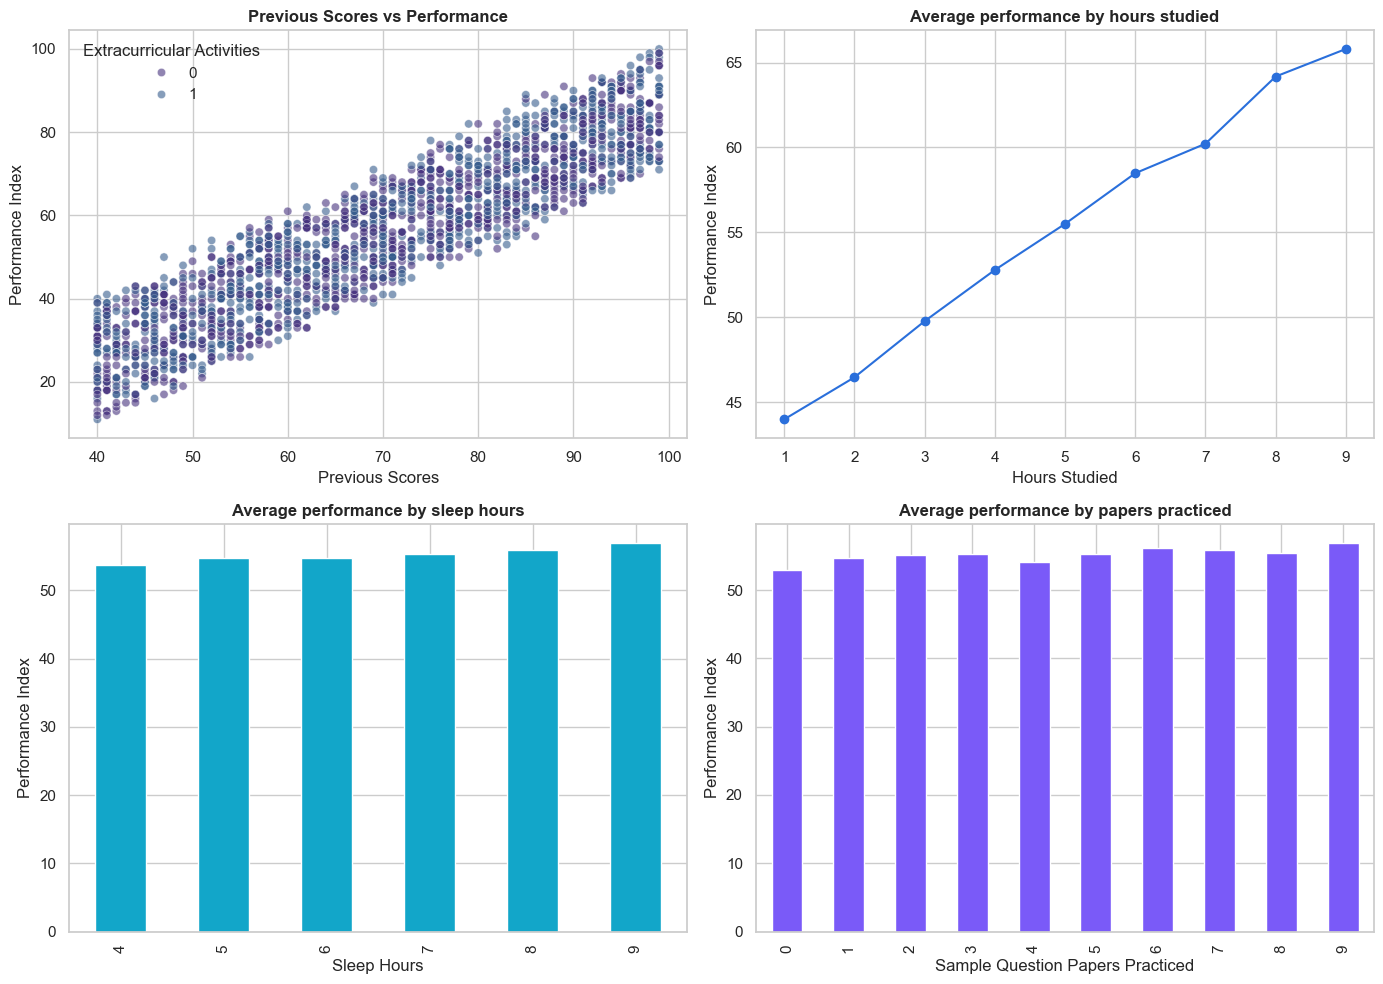

In [49]:
# 3.3 Relationships with the target
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.scatterplot(data=df.sample(2000, random_state=RANDOM_STATE), x="Previous Scores", y=TARGET,
                hue="Extracurricular Activities", alpha=.6, ax=axes[0, 0])
axes[0, 0].set_title("Previous Scores vs Performance")

df.groupby("Hours Studied")[TARGET].mean().plot(marker="o", ax=axes[0, 1], color="#2a6fdb")
axes[0, 1].set_title("Average performance by hours studied")
axes[0, 1].set_ylabel(TARGET)

df.groupby("Sleep Hours")[TARGET].mean().plot(kind="bar", ax=axes[1, 0], color="#12a6c9")
axes[1, 0].set_title("Average performance by sleep hours")
axes[1, 0].set_ylabel(TARGET)

df.groupby("Sample Question Papers Practiced")[TARGET].mean().plot(kind="bar", ax=axes[1, 1], color="#7a5af8")
axes[1, 1].set_title("Average performance by papers practiced")
axes[1, 1].set_ylabel(TARGET)

plt.tight_layout()
plt.show()

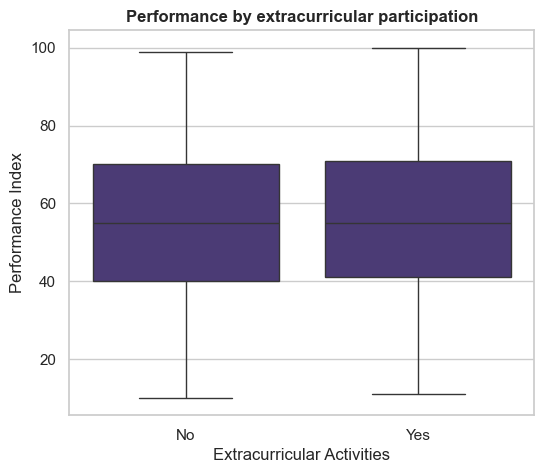

                            count   mean    std
Extracurricular Activities                     
0                            4986 54.721 19.147
1                            4887 55.723 19.260


In [50]:
# 3.4 Extracurricular activities vs performance
plt.figure(figsize=(6, 5))
sns.boxplot(x="Extracurricular Activities", y=TARGET, data=df)
plt.xticks([0, 1], ["No", "Yes"])
plt.title("Performance by extracurricular participation")
plt.show()

print(df.groupby("Extracurricular Activities")[TARGET].agg(["count", "mean", "std"]))

**Observations**
- `Previous Scores` has by far the strongest relationship with the target, followed by `Hours Studied`.
- Sleep, practice papers and extracurricular activities have a small effect on their own, but may help in combination - we test this in the next section.

## 4. Feature Engineering ⚙️

Extra features that try to capture *combined* study behaviour:

| Feature | Idea |
|---|---|
| `Prev_x_Hours` | Strong past scores + more study time reinforce each other |
| `Effort_Score` | Total practice effort: hours studied + papers practiced |
| `Study_Sleep_Ratio` | Study load relative to rest |
| `Well_Rested` | 1 if the student sleeps 7+ hours |
| `Study_Intensity` | Hours studied weighted by practice papers |

Both feature sets (**Base** and **Engineered**) are compared below.

In [51]:
def add_features(frame: pd.DataFrame) -> pd.DataFrame:
    out = frame.copy()
    out["Prev_x_Hours"] = out["Previous Scores"] * out["Hours Studied"] / 100
    out["Effort_Score"] = out["Hours Studied"] + out["Sample Question Papers Practiced"]
    out["Study_Sleep_Ratio"] = out["Hours Studied"] / out["Sleep Hours"]
    out["Well_Rested"] = (out["Sleep Hours"] >= 7).astype(int)
    out["Study_Intensity"] = out["Hours Studied"] * (1 + out["Sample Question Papers Practiced"]) / 10
    return out

BASE_FEATURES = [c for c in df.columns if c != TARGET]
X_base = df[BASE_FEATURES]
X_eng = add_features(X_base)
y = df[TARGET]

print("Base features      :", list(X_base.columns))
print("Engineered features:", list(X_eng.columns))
display(X_eng.head())

Base features      : ['Hours Studied', 'Previous Scores', 'Extracurricular Activities', 'Sleep Hours', 'Sample Question Papers Practiced']
Engineered features: ['Hours Studied', 'Previous Scores', 'Extracurricular Activities', 'Sleep Hours', 'Sample Question Papers Practiced', 'Prev_x_Hours', 'Effort_Score', 'Study_Sleep_Ratio', 'Well_Rested', 'Study_Intensity']


,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Prev_x_Hours,Effort_Score,Study_Sleep_Ratio,Well_Rested,Study_Intensity
0,7,99,1,9,1,6.930,8,0.778,1,1.400
1,4,82,0,4,2,3.280,6,1.000,0,1.200
2,8,51,1,7,2,4.080,10,1.143,1,2.400
3,5,52,1,5,2,2.600,7,1.000,0,1.500
4,7,75,0,8,5,5.250,12,0.875,1,4.200


In [52]:
# One shared train/test split (same rows for both feature sets)
idx_train, idx_test = train_test_split(df.index, test_size=0.2, random_state=RANDOM_STATE)

data = {
    "Base":       (X_base.loc[idx_train], X_base.loc[idx_test]),
    "Engineered": (X_eng.loc[idx_train],  X_eng.loc[idx_test]),
}
y_train, y_test = y.loc[idx_train], y.loc[idx_test]
print(f"Train: {len(idx_train):,} rows | Test: {len(idx_test):,} rows")

Train: 7,898 rows | Test: 1,975 rows


## 5. Training & Evaluating Regression Models

Five regression models, each trained on both feature sets, scored with:
**5-fold cross-validated R²** (train only) and **MAE / RMSE / R²** on the untouched test set.

In [53]:
def make_models():
    return {
        "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
        "Ridge":             make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
        "Lasso":             make_pipeline(StandardScaler(), Lasso(alpha=0.01)),
        "Random Forest":     make_pipeline(StandardScaler(), RandomForestRegressor(
                                 n_estimators=200, min_samples_leaf=3, n_jobs=-1, random_state=RANDOM_STATE)),
        "Gradient Boosting": make_pipeline(StandardScaler(), GradientBoostingRegressor(random_state=RANDOM_STATE)),
    }

kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
fitted = {}      # (model name, feature set) -> fitted pipeline
records = []

def evaluate(name, feats, model):
    X_tr, X_te = data[feats]
    cv = cross_val_score(model, X_tr, y_train, cv=kf, scoring="r2")
    model.fit(X_tr, y_train)
    pred = model.predict(X_te)
    fitted[(name, feats)] = model
    records.append({
        "Model": name, "Features": feats,
        "CV R2 (mean)": cv.mean(), "CV R2 (std)": cv.std(),
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred),
    })

for feats in ["Base", "Engineered"]:
    for name, model in make_models().items():
        evaluate(name, feats, model)

results = pd.DataFrame(records).sort_values("RMSE").reset_index(drop=True)
display(results)

,Model,Features,CV R2 (mean),CV R2 (std),MAE,RMSE,R2
0,Linear Regression,Base,0.989,0.000,1.647,2.075,0.988
1,Ridge,Base,0.989,0.000,1.647,2.075,0.988
2,Linear Regression,Engineered,0.989,0.000,1.647,2.075,0.988
3,Ridge,Engineered,0.989,0.000,1.647,2.075,0.988
4,Lasso,Base,0.989,0.000,1.648,2.076,0.988
5,Lasso,Engineered,0.989,0.000,1.648,2.077,0.988
6,Gradient Boosting,Base,0.988,0.000,1.696,2.139,0.988
7,Gradient Boosting,Engineered,0.987,0.000,1.704,2.144,0.988
8,Random Forest,Engineered,0.986,0.000,1.803,2.259,0.986
9,Random Forest,Base,0.986,0.000,1.814,2.274,0.986


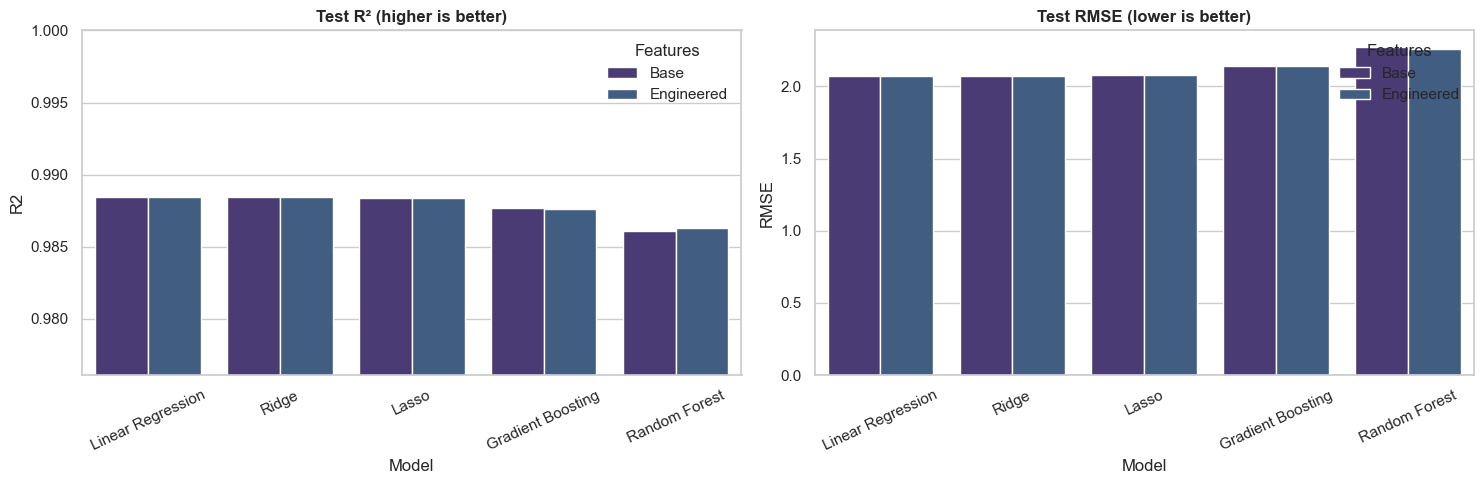

In [54]:
# Visual comparison
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(data=results, x="Model", y="R2", hue="Features", ax=axes[0])
axes[0].set_title("Test R² (higher is better)")
axes[0].set_ylim(results["R2"].min() - 0.01, 1.0)
axes[0].tick_params(axis="x", rotation=25)

sns.barplot(data=results, x="Model", y="RMSE", hue="Features", ax=axes[1])
axes[1].set_title("Test RMSE (lower is better)")
axes[1].tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

## 6. Hyperparameter Tuning

Grid search with 5-fold cross-validation on Gradient Boosting using the engineered features.

In [55]:
param_grid = {
    "gradientboostingregressor__n_estimators": [100, 200, 300],
    "gradientboostingregressor__max_depth": [2, 3, 4],
    "gradientboostingregressor__learning_rate": [0.05, 0.1],
}
grid = GridSearchCV(
    make_pipeline(StandardScaler(), GradientBoostingRegressor(random_state=RANDOM_STATE)),
    param_grid, cv=kf, scoring="neg_root_mean_squared_error", n_jobs=-1,
)
X_tr_e, X_te_e = data["Engineered"]
grid.fit(X_tr_e, y_train)

print("Best params :", grid.best_params_)
print(f"Best CV RMSE: {-grid.best_score_:.3f}")

tuned = grid.best_estimator_
fitted[("Gradient Boosting (tuned)", "Engineered")] = tuned
pred_t = tuned.predict(X_te_e)
records.append({
    "Model": "Gradient Boosting (tuned)", "Features": "Engineered",
    "CV R2 (mean)": cross_val_score(tuned, X_tr_e, y_train, cv=kf, scoring="r2").mean(),
    "CV R2 (std)": np.nan,
    "MAE": mean_absolute_error(y_test, pred_t),
    "RMSE": np.sqrt(mean_squared_error(y_test, pred_t)),
    "R2": r2_score(y_test, pred_t),
})
results = pd.DataFrame(records).sort_values("RMSE").reset_index(drop=True)
display(results)

Best params : {'gradientboostingregressor__learning_rate': 0.05, 'gradientboostingregressor__max_depth': 4, 'gradientboostingregressor__n_estimators': 200}
Best CV RMSE: 2.124


,Model,Features,CV R2 (mean),CV R2 (std),MAE,RMSE,R2
0,Linear Regression,Base,0.989,0.000,1.647,2.075,0.988
1,Ridge,Base,0.989,0.000,1.647,2.075,0.988
2,Linear Regression,Engineered,0.989,0.000,1.647,2.075,0.988
3,Ridge,Engineered,0.989,0.000,1.647,2.075,0.988
4,Lasso,Base,0.989,0.000,1.648,2.076,0.988
5,Lasso,Engineered,0.989,0.000,1.648,2.077,0.988
6,Gradient Boosting,Base,0.988,0.000,1.696,2.139,0.988
7,Gradient Boosting (tuned),Engineered,0.988,NaN,1.697,2.141,0.988
8,Gradient Boosting,Engineered,0.987,0.000,1.704,2.144,0.988
9,Random Forest,Engineered,0.986,0.000,1.803,2.259,0.986


In [56]:
# Pick the overall best model on the test set
best = results.iloc[0]
best_name, best_feats = best["Model"], best["Features"]
best_model = fitted[(best_name, best_feats)]
X_tr_b, X_te_b = data[best_feats]
y_pred = best_model.predict(X_te_b)

print(f"🏆 Best model: {best_name} on {best_feats} features")
print(f"   R²   = {best['R2']:.4f}")
print(f"   MAE  = {best['MAE']:.3f} points")
print(f"   RMSE = {best['RMSE']:.3f} points")

🏆 Best model: Linear Regression on Base features
   R²   = 0.9884
   MAE  = 1.647 points
   RMSE = 2.075 points


## 7. Visualizing Important Results

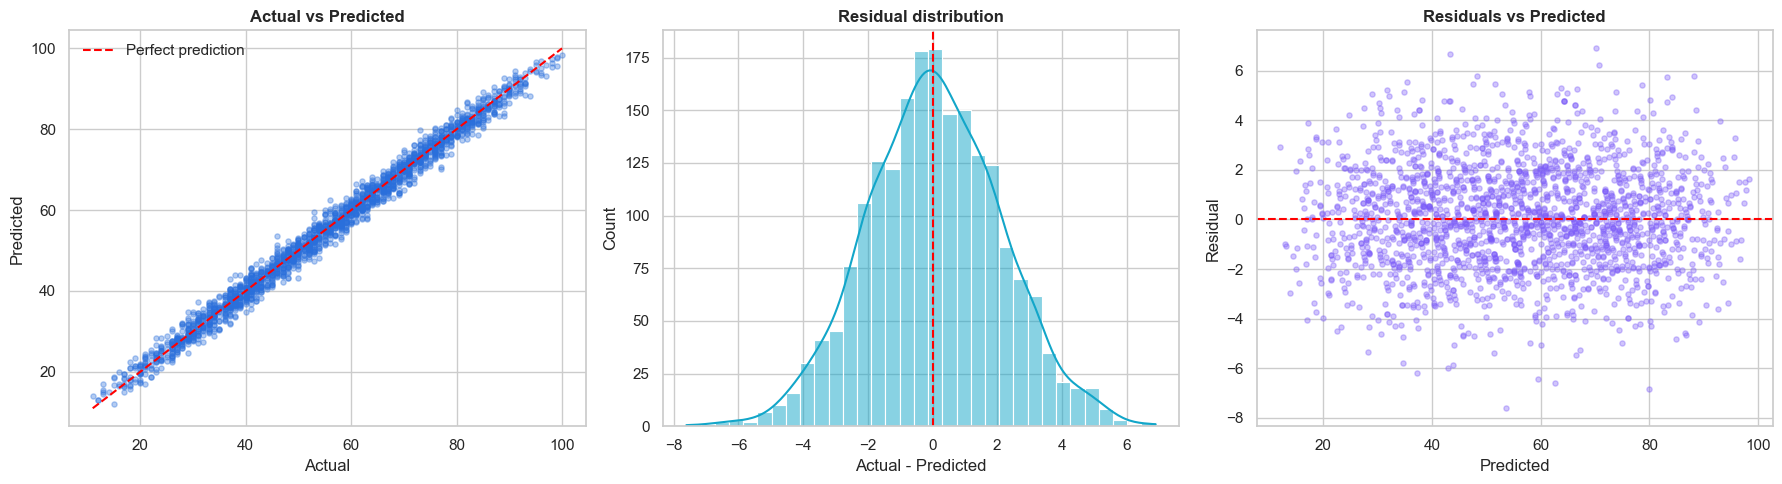

Mean residual: 0.061 | Std: 2.075


In [57]:
residuals = y_test - y_pred
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Actual vs predicted
axes[0].scatter(y_test, y_pred, alpha=.35, s=14, color="#2a6fdb")
lims = [y_test.min(), y_test.max()]
axes[0].plot(lims, lims, "r--", label="Perfect prediction")
axes[0].set_xlabel("Actual"); axes[0].set_ylabel("Predicted")
axes[0].set_title("Actual vs Predicted"); axes[0].legend()

# Residual distribution
sns.histplot(residuals, kde=True, ax=axes[1], color="#12a6c9")
axes[1].axvline(0, color="r", ls="--")
axes[1].set_title("Residual distribution"); axes[1].set_xlabel("Actual - Predicted")

# Residuals vs predicted
axes[2].scatter(y_pred, residuals, alpha=.35, s=14, color="#7a5af8")
axes[2].axhline(0, color="r", ls="--")
axes[2].set_xlabel("Predicted"); axes[2].set_ylabel("Residual")
axes[2].set_title("Residuals vs Predicted")

plt.tight_layout()
plt.show()
print(f"Mean residual: {residuals.mean():.3f} | Std: {residuals.std():.3f}")

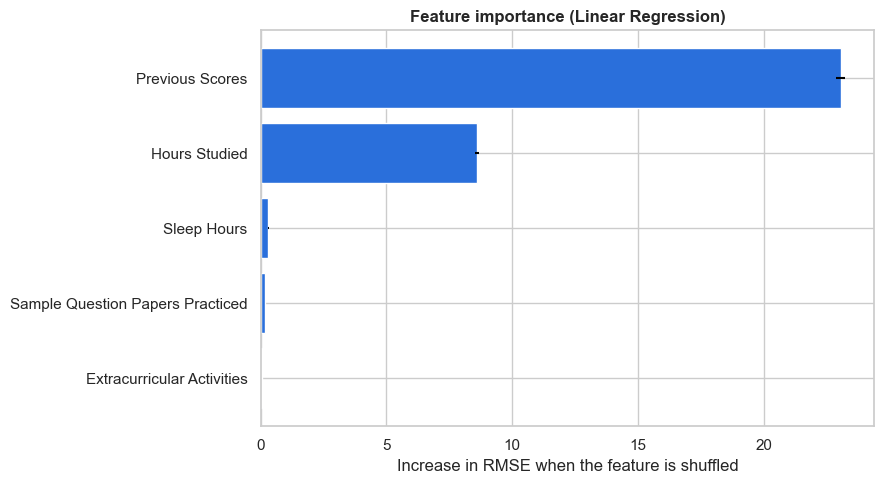

,Feature,Importance,Std
0,Previous Scores,23.063,0.170
1,Hours Studied,8.596,0.069
2,Sleep Hours,0.305,0.021
3,Sample Question Papers Practiced,0.156,0.009
4,Extracurricular Activities,0.055,0.005


In [58]:
# Permutation importance: how much does the error grow when a feature is shuffled?
perm = permutation_importance(best_model, X_te_b, y_test, n_repeats=10,
                              random_state=RANDOM_STATE, scoring="neg_root_mean_squared_error")
imp = (pd.DataFrame({"Feature": X_te_b.columns, "Importance": perm.importances_mean, "Std": perm.importances_std})
         .sort_values("Importance"))

plt.figure(figsize=(9, 5))
plt.barh(imp["Feature"], imp["Importance"], xerr=imp["Std"], color="#2a6fdb")
plt.xlabel("Increase in RMSE when the feature is shuffled")
plt.title(f"Feature importance ({best_name})")
plt.tight_layout()
plt.show()
display(imp.sort_values("Importance", ascending=False).reset_index(drop=True))

In [59]:
# Error by performance range - where does the model struggle?
err = pd.DataFrame({"Actual": y_test, "AbsError": np.abs(residuals)})
err["Range"] = pd.cut(err["Actual"], bins=[0, 40, 60, 80, 100], labels=["10-40", "40-60", "60-80", "80-100"])
display(err.groupby("Range", observed=True)["AbsError"].agg(["count", "mean"]).rename(columns={"mean": "MAE"}))

,count,MAE
Range,,
10-40,496,1.697
40-60,642,1.656
60-80,613,1.610
80-100,224,1.611


## 8. Predicting for 10 Students 🎯

### 8.1 Ten real students from the test set (never seen during training)
Predicted vs. actual performance.

In [60]:
sample_idx = y_test.sample(10, random_state=7).index
sample = df.loc[sample_idx, BASE_FEATURES].copy()
sample["Extracurricular Activities"] = sample["Extracurricular Activities"].map({1: "Yes", 0: "No"})
sample.insert(0, "Student", [f"Student {i}" for i in range(1, 11)])

feat_frame = X_eng.loc[sample_idx] if best_feats == "Engineered" else X_base.loc[sample_idx]
sample["Actual"] = y.loc[sample_idx].values
sample["Predicted"] = best_model.predict(feat_frame).round(1)
sample["Error"] = (sample["Predicted"] - sample["Actual"]).round(1)
sample = sample.reset_index(drop=True)
display(sample)
print(f"Average absolute error on these 10 students: {sample['Error'].abs().mean():.2f} points")

,Student,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Actual,Predicted,Error
0,Student 1,4,84,Yes,6,9,64.000,68.100,4.100
1,Student 2,1,86,No,7,4,60.000,60.500,0.500
2,Student 3,8,81,Yes,6,1,74.000,74.900,0.900
3,Student 4,8,54,No,6,4,49.000,47.400,-1.600
4,Student 5,8,86,Yes,6,0,79.000,79.800,0.800
5,Student 6,5,57,Yes,4,5,41.000,41.700,0.700
6,Student 7,1,68,No,5,9,45.000,42.200,-2.800
7,Student 8,9,72,No,8,2,68.000,69.200,1.200
8,Student 9,3,45,No,5,2,24.000,23.100,-0.900
9,Student 10,4,84,Yes,6,4,67.000,67.100,0.100


Average absolute error on these 10 students: 1.36 points


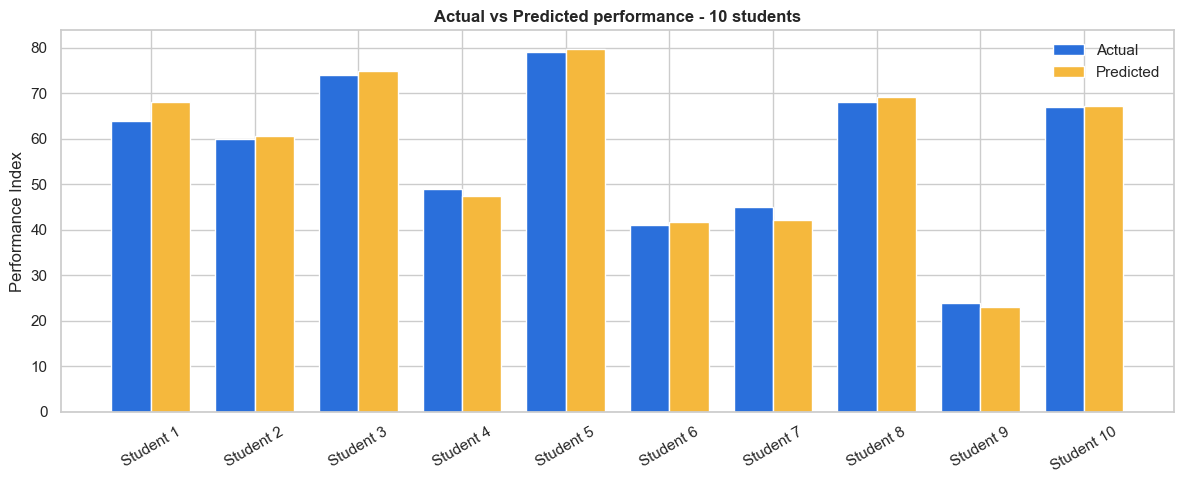

In [61]:
x = np.arange(len(sample))
w = 0.38
plt.figure(figsize=(12, 5))
plt.bar(x - w/2, sample["Actual"], w, label="Actual", color="#2a6fdb")
plt.bar(x + w/2, sample["Predicted"], w, label="Predicted", color="#f5b83d")
plt.xticks(x, sample["Student"], rotation=30)
plt.ylabel(TARGET)
plt.title("Actual vs Predicted performance - 10 students")
plt.legend()
plt.tight_layout()
plt.show()

### 8.2 Ten brand-new students
Edit the table below with your own values and re-run the cell to get predictions for any group of students.

In [62]:
def performance_band(score: float) -> str:
    if score >= 85: return "Excellent"
    if score >= 70: return "Good"
    if score >= 50: return "Average"
    return "Needs support"

def predict_students(students: pd.DataFrame) -> pd.DataFrame:
    # Predict the Performance Index for a DataFrame that has the base columns.
    X = students[BASE_FEATURES].copy()
    X["Extracurricular Activities"] = (X["Extracurricular Activities"].astype(str).str.strip().str.title()
                                      .map({"Yes": 1, "No": 0, "1": 1, "0": 0}))
    if X["Extracurricular Activities"].isna().any():
        raise ValueError("Extracurricular Activities must be Yes/No")
    if best_feats == "Engineered":
        X = add_features(X)
    out = students.copy()
    out["Predicted Performance"] = np.clip(best_model.predict(X), 0, 100).round(1)
    out["Level"] = out["Predicted Performance"].apply(performance_band)
    return out

new_students = pd.DataFrame({
    "Student": [f"New {i}" for i in range(1, 11)],
    "Hours Studied":                    [9, 7, 5, 3, 1, 8, 4, 6, 2, 5],
    "Previous Scores":                  [95, 88, 72, 60, 45, 80, 55, 91, 65, 50],
    "Extracurricular Activities":       ["Yes", "No", "Yes", "No", "No", "Yes", "Yes", "No", "Yes", "No"],
    "Sleep Hours":                      [8, 7, 6, 9, 4, 7, 5, 8, 6, 7],
    "Sample Question Papers Practiced": [8, 5, 4, 2, 0, 6, 3, 9, 1, 4],
})
predictions = predict_students(new_students)
display(predictions)

,Student,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Predicted Performance,Level
0,New 1,9,95,Yes,8,8,94.300,Excellent
1,New 2,7,88,No,7,5,79.800,Good
2,New 3,5,72,Yes,6,4,57.800,Average
3,New 4,3,60,No,9,2,40.300,Needs support
4,New 5,1,45,No,4,0,16.600,Needs support
5,New 6,8,80,Yes,7,6,75.300,Good
6,New 7,4,55,Yes,5,3,36.900,Needs support
7,New 8,6,91,No,8,9,81.300,Good
8,New 9,2,65,Yes,6,1,41.500,Needs support
9,New 10,5,50,No,7,4,35.300,Needs support


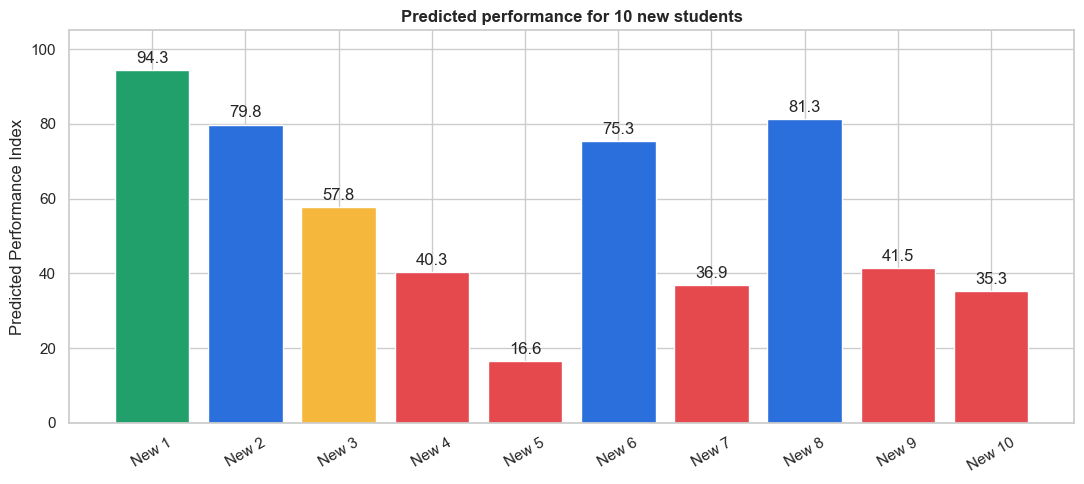

In [63]:
colors = predictions["Level"].map({"Excellent": "#22a06b", "Good": "#2a6fdb", "Average": "#f5b83d", "Needs support": "#e5484d"})
plt.figure(figsize=(11, 5))
bars = plt.bar(predictions["Student"], predictions["Predicted Performance"], color=colors)
plt.bar_label(bars, fmt="%.1f", padding=3)
plt.ylim(0, 105)
plt.ylabel("Predicted Performance Index")
plt.title("Predicted performance for 10 new students")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

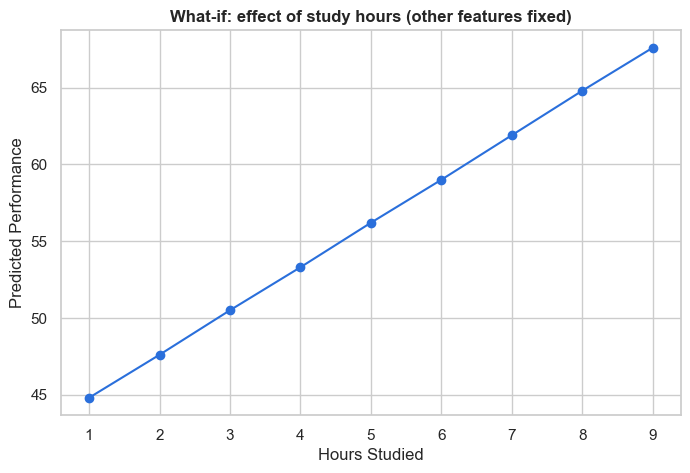

In [64]:
# What-if analysis: how does one extra study hour change the prediction?
base_student = pd.DataFrame([{
    "Student": "Base", "Hours Studied": 5, "Previous Scores": 70, "Extracurricular Activities": "Yes",
    "Sleep Hours": 7, "Sample Question Papers Practiced": 4,
}])
hours = pd.concat([base_student.assign(**{"Hours Studied": h}) for h in range(1, 10)], ignore_index=True)
what_if = predict_students(hours)

plt.figure(figsize=(8, 5))
plt.plot(what_if["Hours Studied"], what_if["Predicted Performance"], marker="o", color="#2a6fdb")
plt.xlabel("Hours Studied"); plt.ylabel("Predicted Performance")
plt.title("What-if: effect of study hours (other features fixed)")
plt.show()

## 9. Saving the Model & Conclusions

In [65]:
joblib.dump({"model": best_model, "features": best_feats, "base_columns": BASE_FEATURES},
            "student_performance_model.joblib")
print("Model saved to student_performance_model.joblib")

# Reload check
bundle = joblib.load("student_performance_model.joblib")
X_check = X_te_b.head(5)
assert np.allclose(bundle["model"].predict(X_check), best_model.predict(X_check))
print("Reload check passed ✅")

Model saved to student_performance_model.joblib
Reload check passed ✅


In [66]:
top = imp.sort_values("Importance", ascending=False).iloc[0]["Feature"]
print("SUMMARY")
print("-" * 50)
print(f"Dataset            : {len(df):,} students after cleaning")
print(f"Best model         : {best_name} ({best_feats} features)")
print(f"Test R²            : {best['R2']:.4f}")
print(f"Test MAE / RMSE    : {best['MAE']:.2f} / {best['RMSE']:.2f} points")
print(f"Most important     : {top}")

SUMMARY
--------------------------------------------------
Dataset            : 9,873 students after cleaning
Best model         : Linear Regression (Base features)
Test R²            : 0.9884
Test MAE / RMSE    : 1.65 / 2.08 points
Most important     : Previous Scores


### Conclusions
- The data was clean (no missing values); duplicate rows were removed.
- **Previous Scores** and **Hours Studied** drive performance the most; sleep, practice papers and extracurricular activities add smaller but real contributions.
- The relationship is almost perfectly linear: plain Linear Regression / Ridge reach R² ≈ 0.988 (MAE ≈ 1.6 points). Random Forest, Gradient Boosting (even tuned) and the engineered features did **not** beat it - they stay within about 0.1 RMSE points of the linear models. The remaining error (~2 points) looks like random noise in the data, so this is close to the ceiling for these five inputs.
- Predictions for 10 test students and 10 new students are shown above, and `predict_students()` can be reused for any group.

### Ideas for future work
- Collect more behavioural features (attendance, tutoring, family support).
- Try XGBoost / LightGBM and stacking ensembles.
- Wrap the saved model in a small web app (Streamlit / Flask).